# noisy: геометрия и CatBoost

Проверяем локальную неровность и изменение меша после слабого сглаживания. Train/validation прежние; internal test для выбора модели не используем.

## 1. Данные

In [1]:
%pip install -q catboost iterative-stratification scipy tqdm

from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from catboost import CatBoostClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/train.csv').is_file()), None)
if ROOT is None:
    ROOT = Path('/content/drive/MyDrive/Colab Notebooks/colab_upload/AI challenge main')
assert (ROOT / 'data/train.csv').is_file(), ROOT
sys.path.insert(0, str(ROOT))
from labels.noisy.noisy_features import FEATURES, R1_FEATURES, extract_one, extract_all
OUT = ROOT / 'labels/noisy'
ART = OUT / 'artifacts'
MODELS = OUT / 'models'
ART.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

labels = pd.read_csv(ROOT / 'data/train.csv')
targets = labels.columns.drop('item_id').tolist()
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_val_idx, test_idx = next(split.split(labels, labels[targets]))
train_val = labels.iloc[train_val_idx].reset_index(drop=True)
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.1765, random_state=43)
train_idx, val_idx = next(split.split(train_val, train_val[targets]))
train = train_val.iloc[train_idx].reset_index(drop=True)
val = train_val.iloc[val_idx].reset_index(drop=True)
objects = pd.concat([train, val], ignore_index=True)
assert (len(train), len(val), len(test_idx)) == (6259, 1361, 1344)
assert set(train.item_id).isdisjoint(val.item_id)
print('Train:', len(train), 'Validation:', len(val), '| noisy:', int(train.noisy.sum()), int(val.noisy.sum()))

Note: you may need to restart the kernel to use updated packages.


C:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 6259 Validation: 1361 | noisy: 1785 382


## 2. Baseline и его ошибки

In [2]:
config = json.loads((ROOT / 'archive/artifacts/catboost_features_config.json').read_text(encoding='utf-8'))
base_columns = config['feature_columns']
threshold = config['thresholds'][targets.index('noisy')]
base = pd.read_csv(ROOT / 'archive/artifacts/train_mesh_features_relative.csv').set_index('item_id')
assert base.index.is_unique and len(base_columns) == 44
old_model = CatBoostClassifier()
old_model.load_model(str(ROOT / 'archive/models/catboost_features/noisy.cbm'))
old_p = old_model.predict_proba(base.loc[val.item_id, base_columns])[:, 1]
y_val = val.noisy.to_numpy()

def score(p, t):
    pred = p >= t
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    return {'Precision': precision_score(y_val, pred), 'Recall': recall_score(y_val, pred),
            'F1': f1_score(y_val, pred), 'AP': average_precision_score(y_val, p),
            'FP': int(fp), 'FN': int(fn), 'Threshold': float(t)}

results = [{'Experiment': 'E1_old44', **score(old_p, threshold)}]
probabilities = val[['item_id', 'noisy']].copy()
probabilities['E1_old44'] = old_p
print('CatBoost 44:', results[0])
fusion_cache = pd.read_csv(ART / 'old_fusion_validation.csv').set_index('item_id').loc[val.item_id]
assert np.array_equal(fusion_cache.noisy.to_numpy(), y_val)
fusion_p = fusion_cache.fusion.to_numpy()
fusion_t = .47
print('Прежняя связка ResNet18 + CatBoost:', score(fusion_p, fusion_t))
for name in ['lowpoly', 'artifacts']:
    group = val[(val.noisy == 1) & (val[name] == 1)]
    missed = int((old_p[group.index] < threshold).sum())
    print(f'noisy + {name}: {len(group)} объектов, {missed} пропусков CatBoost')
for name in ['lowpoly', 'artifacts']:
    group = val[(val.noisy == 1) & (val[name] == 1)]
    print(f'noisy + {name}: {int((fusion_p[group.index] < fusion_t).sum())} пропусков связки')


CatBoost 44:

 {'Experiment': 'E1_old44', 'Precision': 0.7209821428571429, 'Recall': 0.8455497382198953, 'F1': 0.7783132530120482, 'AP': 0.8282895041361852, 'FP': 125, 'FN': 59, 'Threshold': 0.34}
Прежняя связка ResNet18 + CatBoost: {'Precision': 0.7721822541966427, 'Recall': 0.8429319371727748, 'F1': 0.8060075093867334, 'AP': 0.8657843921214711, 'FP': 95, 'FN': 60, 'Threshold': 0.47}
noisy + lowpoly: 12 объектов, 7 пропусков CatBoost
noisy + artifacts: 24 объектов, 2 пропусков CatBoost
noisy + lowpoly: 6 пропусков связки
noisy + artifacts: 2 пропусков связки


## 3. Локальная геометрия и сглаживание

In [3]:
local_columns = ['pca_curvature_mean', 'pca_curvature_p90', 'pca_curvature_p95',
                 'normal_variation_p50', 'normal_variation_p90', 'normal_variation_p95',
                 'normal_variation_std', 'dihedral_over_10_share', 'dihedral_over_30_share']
local = pd.read_csv(ROOT / 'labels/lowpoly/artifacts/geometry_features.csv').set_index('item_id')
assert set(objects.item_id) == set(local.index)
assert not set(base_columns) & set(local_columns + FEATURES)

cache_path = ART / 'smoothing_features.csv'
if (ROOT / 'data/train' / f'{train.item_id.iloc[0]}.npz').is_file():
    checks = [extract_one(item_id, ROOT / 'data/train') for item_id in train.item_id.iloc[:3]]
    display(pd.DataFrame(checks)[['item_id', 'status', 'valid_vertices',
                                  'smooth_r1_p95', 'smooth_r3_p95']].round(5))
else:
    assert cache_path.is_file(), 'Нет NPZ и сохранённых признаков сглаживания'
new = extract_all(objects.item_id, ROOT / 'data/train', cache_path)
assert new.index.is_unique and len(new) == 7620
assert not np.isinf(new[FEATURES].to_numpy(dtype=float)).any()
display(new.status.value_counts())
print('Новых признаков:', len(FEATURES), '| NaN:', int(new[FEATURES].isna().sum().sum()))

,item_id,status,valid_vertices,smooth_r1_p95,smooth_r3_p95
0,0001be62-bf9c-4c15-8a09-dce209be9715,ok,4070,0.00488,0.01146
1,0024dc8f-a2d7-4556-94dc-6b4b0f46ca0d,ok,2958,0.00351,0.00866
2,002b097b-4237-4610-952c-6095d48fb7a0,ok,4302,0.00328,0.00710


Smoothing: 0it [00:00, ?it/s]

Smoothing: 0it [00:00, ?it/s]

status
ok                      7135
no_interior_vertices     484
missing_or_large           1
Name: count, dtype: int64

Новых признаков: 14 | NaN: 6790


## 4. Сравнение признаков

In [4]:
features = base.join(local[local_columns]).join(new[FEATURES])
variants = {
    'E2_local_only': local_columns,
    'E2_base_local': base_columns + local_columns,
    'E3_base_smooth': base_columns + R1_FEATURES,
    'E4_all': base_columns + local_columns + FEATURES,
}
grid = np.arange(.05, .96, .01)
for name, columns in variants.items():
    model = CatBoostClassifier(**config['parameters'])
    model.fit(features.loc[train.item_id, columns], train.noisy,
              eval_set=(features.loc[val.item_id, columns], val.noisy),
              early_stopping_rounds=50, verbose=False)
    p = model.predict_proba(features.loc[val.item_id, columns])[:, 1]
    t = float(max(grid, key=lambda value: f1_score(y_val, p >= value)))
    results.append({'Experiment': name, **score(p, t)})
    probabilities[name] = p
    model.save_model(str(MODELS / f'{name}.cbm'))
    print(name, '| F1:', round(results[-1]['F1'], 4), '| AP:', round(results[-1]['AP'], 4))

table = pd.DataFrame(results).sort_values('F1', ascending=False)
display(table.round(4))
table.to_csv(ART / 'experiments.csv', index=False)
probabilities.to_csv(ART / 'validation_probabilities.csv', index=False)

E2_local_only | F1: 0.7268 | AP: 0.7745


E2_base_local | F1: 0.7969 | AP: 0.8561


E3_base_smooth | F1: 0.7694 | AP: 0.8282


E4_all | F1: 0.8025 | AP: 0.8671


,Experiment,Precision,Recall,F1,AP,FP,FN,Threshold
4,E4_all,0.7636,0.8455,0.8025,0.8671,100,59,0.34
2,E2_base_local,0.7828,0.8115,0.7969,0.8561,86,72,0.41
0,E1_old44,0.7210,0.8455,0.7783,0.8283,125,59,0.34
3,E3_base_smooth,0.7273,0.8168,0.7694,0.8282,117,70,0.37
1,E2_local_only,0.7157,0.7382,0.7268,0.7745,112,100,0.41


## 5. Ошибки лучшего варианта

noisy + lowpoly: 12 объектов, 6 пропусков
noisy + artifacts: 24 объектов, 4 пропусков


,item_id,noisy,lowpoly,artifacts,probability,prediction
464,579baaa7-b7dd-47c3-a6a4-1e72c92e741c,0,0,1,0.958668,1
852,a07adb97-acac-45bb-933a-30d94c75f05c,0,0,1,0.952708,1


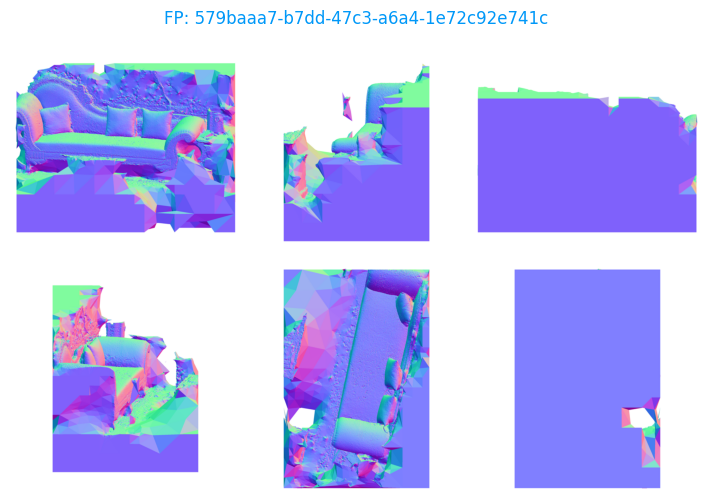

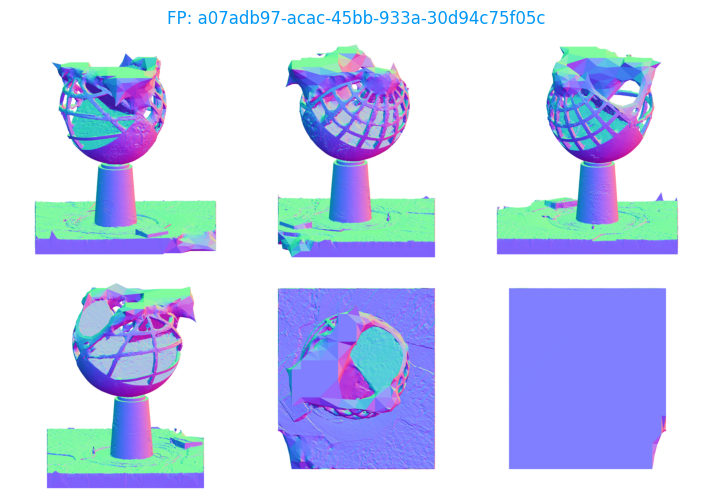

,item_id,noisy,lowpoly,artifacts,probability,prediction
243,2ed48369-64ec-4152-afc4-1fe510e68a5a,1,0,0,0.004181,0
677,825e7bc8-613e-4e36-9c95-914b54406938,1,0,0,0.006713,0


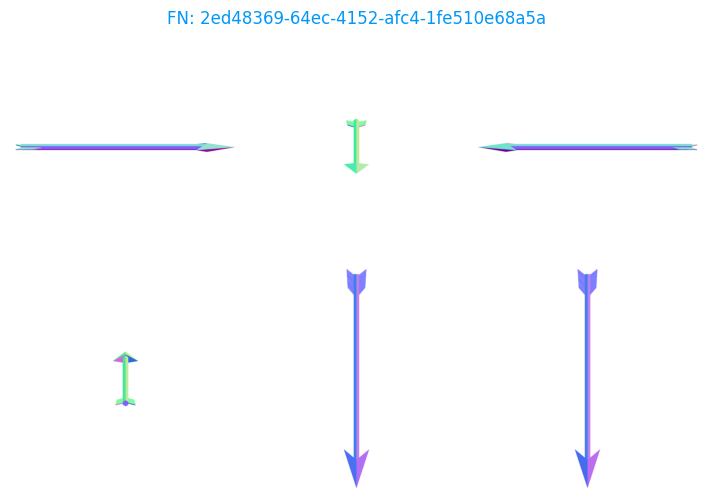

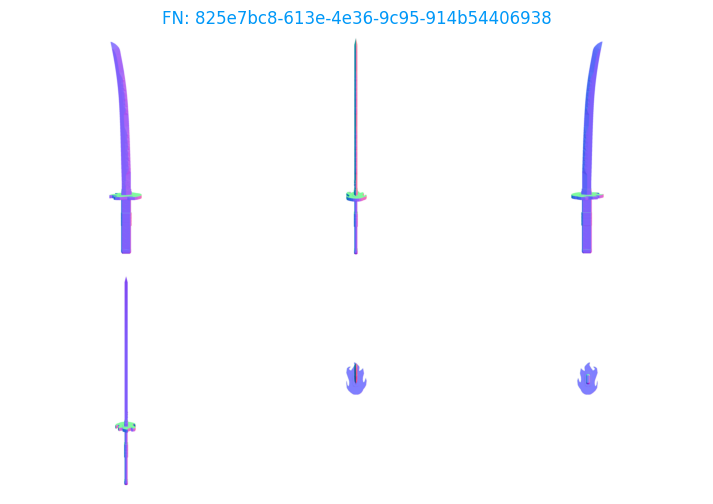

smooth_r3_to_r1_p50        7.28
surface_area_relative      5.44
faces_count                4.43
edge_std_relative          3.77
smooth_r1_local_over_01    3.73
edge_variation             3.47
faces_per_vertex           2.99
edge_std                   2.92
normal_variation_p50       2.90
dihedral_over_10_share     2.57
pca_curvature_mean         2.48
min_to_max                 2.48
dtype: float64

Лучший вариант: E4_all | F1: 0.8025
Относительно прежней связки:
Исправлено FN: 20 | новых FN: 19
Исправлено FP: 27 | новых FP: 32


In [5]:
best = table.iloc[0]
p = probabilities[best.Experiment].to_numpy()
t = best.Threshold
review = val[['item_id', 'noisy', 'lowpoly', 'artifacts']].copy()
review['probability'] = p
review['prediction'] = (p >= t).astype(int)
for name in ['lowpoly', 'artifacts']:
    group = review[(review.noisy == 1) & (review[name] == 1)]
    print(f'noisy + {name}: {len(group)} объектов, {int((group.prediction == 0).sum())} пропусков')

for title, subset in [('FP', review.query('noisy == 0 and prediction == 1')),
                      ('FN', review.query('noisy == 1 and prediction == 0'))]:
    sample = subset.sort_values('probability', ascending=title == 'FN').head(2)
    display(sample)
    for item_id in sample.item_id:
        with Image.open(ROOT / 'data/train' / f'{item_id}.png') as image:
            plt.figure(figsize=(12, 6))
            plt.imshow(image.convert('RGB'))
            plt.title(f'{title}: {item_id}', color='#0098F8')
            plt.axis('off')
            plt.show()

if best.Experiment != 'E1_old44':
    model = CatBoostClassifier()
    model.load_model(str(MODELS / f'{best.Experiment}.cbm'))
    importance = pd.Series(model.get_feature_importance(), index=variants[best.Experiment])
    display(importance.nlargest(12).round(2))
print('Лучший вариант:', best.Experiment, '| F1:', round(best.F1, 4))
old_pred = fusion_p >= fusion_t
new_pred = p >= t
print('Относительно прежней связки:')
print('Исправлено FN:', int(((y_val == 1) & ~old_pred & new_pred).sum()),
      '| новых FN:', int(((y_val == 1) & old_pred & ~new_pred).sum()))
print('Исправлено FP:', int(((y_val == 0) & old_pred & ~new_pred).sum()),
      '| новых FP:', int(((y_val == 0) & ~old_pred & new_pred).sum()))
